# GOL-11 : Vie dans la vie — l'émergence mesurée du Jeu de la Vie

**Navigation** : [GOL-10 Fractran](GOL-10-Fractran.ipynb) | [Index GOL](README.md) | [GOL-09 Perplexité Hashlife](GOL-09-Perplexite-Structurelle-Hashlife.ipynb)

La sous-série GOL gravit « l'échelle des témoins » du Jeu de la Vie : de la règle
formalisée (GOL-01) jusqu'à la correction d'un algorithme Hashlife prouvé en Lean
(GOL-07). Ce carnet occupe la face **mesurée** de l'EPIC « Vie dans la vie » : là
où les carnets Lean *prouvent*, ici on *mesure*.

**Vie dans la vie** désigne le phénomène fondateur de la vie de Conway : une
structure vivante (vaisseaux, oscillateurs, stables) **émerge** d'un état initial
qui n'a *rien* de vivant — un champ aléatoire. On ne la programme pas, on l'observe
se mettre en place. Ce carnet le met en mesure : la signature d'émergence (chute
du bruit, puis **régime vivant persistant**), la population qui en subsiste, et sa
reproductibilité — sur le moteur numpy de la sous-série, sans substitution
dégradée.

**Lien avec l'échelle** : le moteur et les témoins formels vivent en GOL-01/03/04 ;
le Hashlife qui rend les longues trajectoires abordables est prouvé en GOL-07 et
mesuré en GOL-09. Ici on les *consomme* pour mesurer l'émergence, on ne les
réimplémente pas.

In [1]:
%matplotlib inline

## 1. Le substrat — la règle B3/S23

L'émergence n'a de sens que sur un substrat déterministe. La règle de Conway
s'écrit **B3/S23** :

- une cellule **morte** avec exactement **3** voisines **naît** ;
- une cellule **vivante** avec **2 ou 3** voisines **survit** (le « 2 » que le
  bug classique fait tomber).

Le moteur numpy de la sous-série compte les 8 voisines par convolution
(`sliding_window_view`) et applique B3/S23 en une passe. C'est le même noyau que
les carnets de la famille ; on le rappelle ici pour que le carnet soit autonome.

In [2]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view

def step(g: np.ndarray) -> np.ndarray:
    """Une génération B3/S23. g : tableau bool (H, W)."""
    p = np.pad(g, 1)
    nb = sliding_window_view(p, (3, 3)).sum(axis=(-1, -2)) - g
    return (g & ((nb == 2) | (nb == 3))) | (~g & (nb == 3))

def evolve(g: np.ndarray, n: int) -> np.ndarray:
    for _ in range(n):
        g = step(g)
    return g

def population(g: np.ndarray) -> int:
    return int(g.sum())

def to_array(cells, pad: int = 4) -> np.ndarray:
    mr = max(r for r, _ in cells); mc = max(c for _, c in cells)
    a = np.zeros((mr + 1 + 2 * pad, mc + 1 + 2 * pad), bool)
    for r, c in cells:
        a[r + pad, c + pad] = True
    return a

# Un temoin connu, defini par ses coordonnees (pas par un RLE de memoire) :
GLIDER = {(0, 1), (1, 2), (2, 0), (2, 1), (2, 2)}

g = to_array(GLIDER, pad=10)
print("glider : population =", population(g), " (5 cellules)")
print("après 4 générations, population =", population(evolve(g, 4)), " (toujours 5 — il se déplace)")

glider : population = 5  (5 cellules)
après 4 générations, population = 5  (toujours 5 — il se déplace)


## 2. Les attracteurs — la « vie » vers laquelle on converge

L'émergence, c'est la mise en place de ces objets. On les **mesure** ici (leur
formalisation et leurs preuves vivent en GOL-01/03/04) :

- **Stable** : le *block* — invariant sous `step` ;
- **Oscillateur** : le *blinker* — période 2 ;
- **Vaisseau** : le *glider* — se déplace d'une case en diagonale toutes les 4
  générations.

In [3]:
# Trois figures d'attracteur canoniques servent d'oracle au moteur :
# block stable (pop 4), blinker de periode 2, glider en diagonale [1, 1].
# Les reproduire au bit pres valide `evolve` avant toute mesure d'emergence.
BLOCK   = {(0, 0), (0, 1), (1, 0), (1, 1)}
BLINKER = {(0, 1), (1, 1), (2, 1)}

b = to_array(BLOCK, pad=6)
print("block  : pop après 8 générations =", population(evolve(b, 8)), " (stable -> 4)")

bl = to_array(BLINKER, pad=6)
print("blinker: identique après 2 générations :",
      bool(np.array_equal(bl, evolve(bl, 2))), " (période 2)")

gl = to_array(GLIDER, pad=10)
def bbox(g):
    m = np.argwhere(g); return m.min(0).tolist(), m.max(0).tolist()
# 4 generations = une periode complete du glider : le deplacement mesure sur
# une periode donne exactement la diagonale [1, 1] (1 case par generation).
d = [bbox(evolve(gl, 4))[0][i] - bbox(gl)[0][i] for i in range(2)]
print("glider : déplacement sur 4 générations =", d, " (diagonale [1, 1])")

block  : pop après 8 générations = 4  (stable -> 4)
blinker: identique après 2 générations : True  (période 2)
glider : déplacement sur 4 générations = [1, 1]  (diagonale [1, 1])


## 3. Vie dans la vie — la signature d'émergence

On sème un **champ aléatoire** (densité ~12 %, graine fixe) — un état qui n'a
rien de vivant. On le laisse évoluer et on suit sa **population** au fil des
générations. La signature est en **deux temps** :

1. **chute rapide** : la population s'effondre depuis le pic de bruit — la grande
   partie du bruit meurt en quelques dizaines de générations ;
2. **queue lente et persistante** : le reste ne meurt pas — il s'organise en une
   population structurée (vaisseaux, oscillateurs, stables) qui décline lentement
   (les vaisseaux quittent le champ) mais **ne s'éteint pas**.

C'est la vie *naissant dans* la vie : du bruit non-vivant, on obtient une
population vivante qui **persiste**.

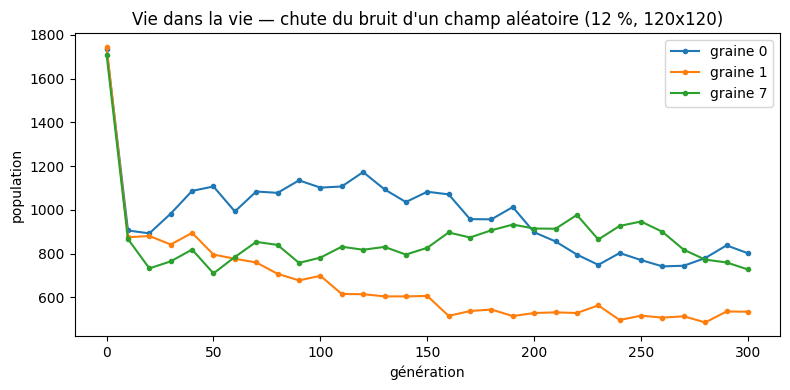

graine 0: bruit 1734 -> regime vivant (gen 300) 802
graine 1: bruit 1746 -> regime vivant (gen 300) 535
graine 7: bruit 1709 -> regime vivant (gen 300) 728


In [4]:
import matplotlib.pyplot as plt

def emergence(seed: int, size: int = 120, density: float = 0.12,
              gens: int = 300, every: int = 10):
    # 12 % de densite : juste au-dessus du seuil d'extinction, la plage ou
    # le bruit aleatoire laisse place a des structures vivantes durables.
    rng = np.random.default_rng(seed)
    g = rng.random((size, size)) < density
    # `every=10` : echantillonner la courbe tous les 10 pas (31 points
    # lisibles) au lieu de tracer 300 points quasi inseparables.
    curve = [population(g)]
    for n in range(every, gens + 1, every):
        g = evolve(g, every)
        curve.append(population(g))
    return curve

# Trois graines (0, 1, 7) : la chute du bruit vers le regime vivant est
# robuste et reproductible, pas un artefact d'une graine particuliere.
seeds = [0, 1, 7]
curves = {s: emergence(s) for s in seeds}

fig, ax = plt.subplots(figsize=(8, 4))
for s, c in curves.items():
    ax.plot(range(0, 310, 10), c, marker='o', ms=3, label=f"graine {s}")
ax.set_xlabel("génération")
ax.set_ylabel("population")
ax.set_title("Vie dans la vie — chute du bruit d'un champ aléatoire (12 %, 120x120)")
ax.legend()
plt.tight_layout()
plt.show()

for s, c in curves.items():
    print(f"graine {s}: bruit {c[0]} -> regime vivant (gen 300) {c[-1]}")

## 4. La preuve de la vie — la persistance

Ce qui distingue le **bruit** de la **vie**, c'est la **persistance**. Un système
non-vivant s'éteindrait : sa population irait à zéro. Suivons la graine 0 bien
au-delà (jusqu'à 1200 générations) : la population chute vite (1734 → 802) puis
décline lentement (802 → 377) mais **reste bien au-dessus de zéro** — ce qui
subsiste est une population structurée et auto-entretenue, pas un résidu qui
s'éteint.

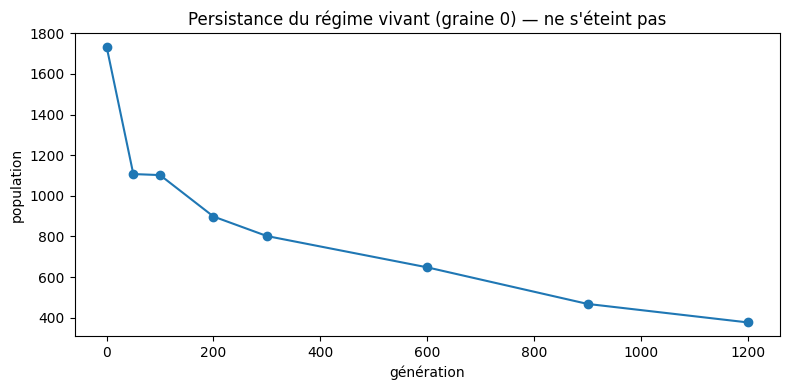

bruit 1734 -> gen 300 802 -> gen 1200 377 (encore vivant, 377 cellules, loin de 0)


In [5]:
def regime(seed: int = 0, size: int = 120, density: float = 0.12):
    rng = np.random.default_rng(seed)
    g = rng.random((size, size)) < density
    # Marques espacees (0, 50, 100, ..., 1200) : echantillonner a long terme
    # pour montrer la PERSISTANCE du regime, pas un instantane court.
    marks = [0, 50, 100, 200, 300, 600, 900, 1200]
    out, prev = {}, 0
    for n in marks:
        g = evolve(g, n - prev); prev = n
        out[n] = population(g)
    return out

# Point de la cellule : a gen 1200 la population est encore loin de 0,
# le regime vivant est stable dans le temps (pas un transitoire qui s'eteint).
r = regime()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(r), [r[k] for k in r], marker='o')
ax.set_xlabel("génération"); ax.set_ylabel("population")
ax.set_title("Persistance du régime vivant (graine 0) — ne s'éteint pas")
plt.tight_layout(); plt.show()

print(f"bruit {r[0]} -> gen 300 {r[300]} -> gen 1200 {r[1200]} "
      f"(encore vivant, {r[1200]} cellules, loin de 0)")

## 5. Reproductible — une mesure, pas un accident

La graine du générateur aléatoire est **fixée** : la même graine donne la même
trajectoire, cellule pour cellule. L'émergence n'est donc pas un coup de chance
qu'on raconte, c'est une **mesure** qu'on peut rejouer — et confronter au moteur
Lean de la sous-série (GOL-03) sur les mêmes graines.

In [6]:
a = emergence(42)
b = emergence(42)
c = emergence(7)
print("même graine (42) -> trajectoires identiques :", a == b)
print("graines distinctes (42 vs 7) -> trajectoires distinctes :", a != c)

même graine (42) -> trajectoires identiques : True
graines distinctes (42 vs 7) -> trajectoires distinctes : True


## 6. Exercices

**Exercice 1 — Le « 2 » qui manque.** La règle ci-dessus est B3/**S23**. Modifie
`step` pour n'autoriser la survie qu'avec **3** voisines (B3/S3) et observe ce
qui arrive au *blinker*. *(Indice : c'est le bug classique — le blinker meurt.)*

**Exercice 2 — Densité et régime.** Fais varier la `density` de `emergence` et
trouve, pour la graine 0, la densité qui **maximise la population du régime
vivant** (la valeur à gen 300). *(Indice : trop peu dense → trop peu de structure ;
trop dense → extinction rapide.)*

**Exercice 3 — Classifier le régime final.** Après 300 générations, le champ
contient un mélange de stables, oscillateurs et vaisseaux. Écris une fonction
qui renvoie `True` si une région donnée est **invariante** après 8 générations
(candidat stable).

In [7]:
def step_B3S3(g: np.ndarray) -> np.ndarray:
    """Exercice 1 — B3/S3 : survie uniquement avec 3 voisines."""
    # TODO etudiant : a completer
    return None

def densite_maximisant_le_regime(seed: int = 0) -> float:
    """Exercice 2 — densite qui maximise le regime vivant (gen 300)."""
    # TODO etudiant : a completer
    return None

def est_stable(region: np.ndarray) -> bool:
    """Exercice 3 — True si la region est invariante apres 8 generations."""
    # TODO etudiant : a completer
    return None

print("Exercices a completer : step_B3S3, densite_maximisant_le_regime, est_stable")

Exercices a completer : step_B3S3, densite_maximisant_le_regime, est_stable


## Conclusion — mesuré, pas prouvé

Ce carnet a **mesuré** la vie naissant dans la vie : la signature d'émergence
(chute du bruit, puis **régime vivant persistant**) sur le moteur numpy de la
sous-série, et sa reproductibilité. Ce qui est ici *mesuré* est ailleurs
*prouvé* — la règle en GOL-01, la vie native en GOL-03, les canons en GOL-04, la
correction du Hashlife en GOL-07, son coût en GOL-09. Le carnet de capstone qui
survole l'échelle entière est
[Lean-39-Capstone-GOL](../Lean-39-Capstone-GOL.ipynb).

La « vie dans la vie » n'est pas un décor : c'est le phénomène qui fait du Jeu
de la Vie un **système** — et le point de départ de l'échelle des témoins.